# Week 6 — Reservoir readout and first closed loop

**Goal: the fly brain moves the arm.** The connectome stays frozen. The only thing trained is a linear readout (ridge regression) from the descending-neuron rates to the expert's action.

One control step (40 ms), all code in `sim/closed_loop.py`:

| | |
|---|---|
| **arm state → encoder** | cube − gripper x, y, z and gripper width → push/pull Poisson rates on the 335 JO-C/E neurons (the week 5 *wiring* encoder, `encoder_wiring.json`) |
| **N brain steps** | the full male-CNS network advances 40 ms (400 steps of 0.1 ms) on the Numba engine, `BrainIO.step`, the same call week 5 replayed |
| **decoder** | rates of the 68 week 1 DN candidates over those 40 ms |
| **readout** | ridge regression → gripper dx, dy, dz (gripper held open: reaching only) |
| **controller → physics** | week 4 IK controller, 40 ms of MuJoCo |

**Training: DAgger.** Round 0 lets the expert drive while the brain watches (half the episodes with 5 mm action noise, as in week 4). Rounds 1–3 let the brain drive; every state it visits is labelled with what the expert would do there, and the readout is refit on everything so far. The expert is memoryless (week 4), so it can label any state the brain wanders into. This matters because week 4 showed that imitators trained only on clean expert data fall apart once their own errors move them off the expert's path.

**Reach task, fixed before any brain run**
- **reached:** gripper within 15 mm of the cube in x-y **and** below 4.2 cm, held for 5 steps (0.2 s). These are the expert's own "ready to close" tolerances.
- **travel:** gripper within 15 mm in x-y at any height (the first half of the reach).
- **knocked:** cube pushed more than 10 mm → failure, the episode stops.
- **timeout:** 75 steps (3 s). The expert needs 15 steps (median) and 17 at most.

**Pass rule, fixed in advance** (50 fresh evaluation seeds, never used in training):
1. brain reach success **≥ 70%**, and
2. it beats the **cut-feedback control** (the same brain and readout, but the brain only ever sees the first state), so the arm is really steered by what the brain senses, not by a fixed drift learned into the readout.

**References run on the same seeds without the brain:** the expert, and the same ridge readout applied straight to the 4 noise-free encoded signals. The second one is the linear baseline the brain is compared with.

**Where to run:** the laptop (`sim-env`), about 25–45 min, most of it brain time. `QUICK = True` is a 6-minute smoke test. Colab also works.

### Setup

In [1]:
import sys, subprocess, os
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
    try:
        import brian2, numba, mujoco, imageio_ffmpeg
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'brian2', 'numba', 'mujoco',
                        'imageio', 'imageio-ffmpeg'], check=True)
        print("packages installed -> restarting runtime. When it reconnects, choose Runtime -> Run all again.")
        os.kill(os.getpid(), 9)
except ImportError:
    IN_COLAB = False

from pathlib import Path
BRAIN = Path('/content/drive/MyDrive/arm_simulation/brain') if IN_COLAB else Path.home() / 'arm_simulation/brain'
DATA = BRAIN / 'data'
# week 4 arm code (panda_env.py, expert.py): the first folder that has it is used
ARM = next((p for p in [BRAIN.parent / 'arm', BRAIN.parent / 'week4/arm'] if (p / 'panda_env.py').exists()), None)
sys.path.insert(0, str(BRAIN))
if ARM: sys.path.insert(0, str(ARM))

QUICK = False        # True: 3 short DAgger rounds, 10 test seeds, no video re-runs beyond one (about 6 min)

for p in ['sim/lif.py', 'sim/lif_numba.py', 'sim/interface.py', 'sim/readout.py', 'sim/closed_loop.py',
          'sim/video.py', 'data/weights_male-cns_v1.0/meta.json', 'data/shortlist_week1.csv',
          'data/wsyn_choice.json', 'data/week5/encoder_wiring.json']:
    print(f"{p:45s} {'ok' if (BRAIN / p).exists() else 'MISSING'}")
print(f"{'week 4 arm code':45s} {ARM if ARM else 'MISSING - put panda_env.py and expert.py in ' + str(BRAIN.parent / 'arm')}")
if ARM:
    print(f"{'mujoco_menagerie next to arm/':45s} {'ok' if (ARM.parent / 'mujoco_menagerie/franka_emika_panda').exists() else 'MISSING'}")

sim/lif.py                                    ok
sim/lif_numba.py                              ok
sim/interface.py                              ok
sim/readout.py                                ok
sim/closed_loop.py                            ok
sim/video.py                                  ok
data/weights_male-cns_v1.0/meta.json          ok
data/shortlist_week1.csv                      ok
data/wsyn_choice.json                         ok
data/week5/encoder_wiring.json                ok
week 4 arm code                               /home/notlord/arm_simulation/arm
mujoco_menagerie next to arm/                 ok


### Load the brain, the encoder and the arm

In [2]:
import json, time, gc, pickle
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings('ignore', module='brian2')
from sim.lif import WeightSet, peak_mem_gb
from sim.lif_numba import NumbaLIF
from sim.interface import Encoder, BrainIO, SIGNALS
from sim.readout import cv_r2, r2
from sim.closed_loop import (BrainPolicy, SignalPolicy, ExpertPolicy, RidgeReadout, run_episode,
                             dagger, evaluate, summarise, wilson, REACH_XY, REACH_Z, REACH_MAX_STEPS)
from panda_env import PandaPickPlace, OBS_NAMES
from expert import expert

T_START = time.perf_counter()
HOST = 'colab' if IN_COLAB else 'laptop'
OUT = DATA / 'week6'; OUT.mkdir(exist_ok=True)

ws = WeightSet(DATA / 'weights_male-cns_v1.0')
W = json.loads((DATA / 'wsyn_choice.json').read_text())['w_scale']
ENC = Encoder.from_json(DATA / 'week5' / 'encoder_wiring.json')
JO = ws.by_type(r'^JO-(C|E)', cls='cb_sensory')
assert set(ENC.neurons) == set(JO), "encoder_wiring.json does not match this weight set's JO-C/E neurons"
shortlist = pd.read_csv(DATA / 'shortlist_week1.csv')
g2i = pd.Series(ws.neurons.index, index=ws.neurons.bodyId)
DN_cand = g2i.loc[shortlist.query("group == 'middle_descending'").bodyId].to_numpy()
ALL_DN = ws.idx(ws.neurons['cls'].astype(str).str.contains('descending', case=False))
if len(ALL_DN) == 0:
    ALL_DN = DN_cand
RECORD = np.unique(np.r_[DN_cand, ALL_DN])                 # rates of all of these are logged
col = pd.Series(np.arange(len(RECORD)), index=RECORD)
COLS = {'DN candidates': col.loc[DN_cand].to_numpy(), 'all DNs': col.loc[ALL_DN].to_numpy()}

t0 = time.perf_counter()
eng = NumbaLIF(ws.subnetwork(np.arange(ws.N)), ENC.neurons)   # stimulus order = encoder order
io = BrainIO(eng, ENC, RECORD)
env = PandaPickPlace()
print(f"brain built in {time.perf_counter() - t0:.0f} s, peak memory {peak_mem_gb():.2f} GB")
print(f"w_scale {W}, encoder {ENC.kind} ({len(ENC.neurons)} JO-C/E), DN candidates {len(DN_cand)}, "
      f"all DNs {len(ALL_DN)}")

# seeds: training and test never overlap, and no seed was used in weeks 4-5
N_ROUNDS = 3 if QUICK else 4
N_PER_ROUND = 6 if QUICK else 30
TRAIN_SEEDS = [list(range(60_000 + 1000 * r, 60_000 + 1000 * r + N_PER_ROUND)) for r in range(N_ROUNDS)]
BETAS = [1.0] + [0.0] * (N_ROUNDS - 1)                    # round 0: expert drives; then the brain
TEST_SEEDS = list(range(90_000, 90_000 + (10 if QUICK else 50)))
CUT_SEEDS = TEST_SEEDS[:10 if QUICK else 20]

C = dict(blue='#2a78d6', orange='#eb6834', aqua='#1baf7a', yellow='#eda100', violet='#6250d6',
         red='#d03b3b', gray='#9a9893', ink='#0b0b0b', ink2='#52514e', grid='#e6e5e1')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'font.size': 9, 'axes.titlesize': 10,
                     'axes.titleweight': 'bold', 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': C['ink2'], 'axes.labelcolor': C['ink2'], 'xtick.color': C['ink2'],
                     'ytick.color': C['ink2'], 'axes.grid': True, 'grid.color': C['grid'], 'grid.linewidth': 0.6,
                     'axes.axisbelow': True, 'legend.frameon': False, 'lines.linewidth': 2})

numba on cpu: 176,422 neurons, 24,287,791 connections, built in 12.4 s
brain built in 25 s, peak memory 2.29 GB
w_scale 0.7, encoder wiring (335 JO-C/E), DN candidates 68, all DNs 1332


## Step 1: references without the brain (about 30 s)

- **Expert** on the reach task: the ceiling.
- **Linear readout on the 4 encoded signals**, trained with exactly the same DAgger rounds and seeds the brain will get. Week 5 worried that a linear map can't produce the expert's "align first, then descend" cutoff. This shows whether that matters for reaching. If this baseline already reaches, the brain does not need to add nonlinearity to pass; it needs to *carry* the signals well enough through 40 ms of spiking.

In [3]:
REF = {}
REF['expert'] = evaluate(env, ExpertPolicy(expert, OBS_NAMES), expert, TEST_SEEDS, label='expert')
sig = SignalPolicy(OBS_NAMES)
_, sig_data, sig_log = dagger(env, sig, expert, TRAIN_SEEDS, BETAS)
REF['signals'] = evaluate(env, sig, expert, TEST_SEEDS, label='linear readout on the 4 signals (no brain)')

  expert: reach 50/50 (100%, 95% CI 93%-100%), travel 100%, knocked 0%, median time 15.0 steps  [3 s]
  round 0 (expert drives): 30 episodes, success while collecting 87%, knocked 13%; refit on 672 rows, alpha 0.316  [2 s]
  round 1 (signals drives): 30 episodes, success while collecting 100%, knocked 0%; refit on 1,376 rows, alpha 0.316  [3 s]
  round 2 (signals drives): 30 episodes, success while collecting 100%, knocked 0%; refit on 2,045 rows, alpha 0.316  [5 s]
  round 3 (signals drives): 30 episodes, success while collecting 100%, knocked 0%; refit on 2,706 rows, alpha 3.16  [7 s]
  linear readout on the 4 signals (no brain): reach 50/50 (100%, 95% CI 93%-100%), travel 100%, knocked 0%, median time 17.0 steps  [3 s]


## Step 2: train the brain readout with DAgger

Each episode: fresh brain (seed = episode seed), held 200 ms at the first state, then one 40 ms brain advance per control step. The rates of all recorded descending neurons are logged, so the readout pool can be changed later without rerunning the brain; the readout itself uses the **68 DN candidates** (the week 5 decision).

A checkpoint (data and readout) is saved after every round in `data/week6/`. About 12–30 min on the laptop: an episode the brain finishes takes about 5 s, one that runs to the 3 s timeout about 15 s.

In [4]:
pol = BrainPolicy(io, W, OBS_NAMES, cols=COLS['DN candidates'], raster_cols=COLS['DN candidates'])

def checkpoint(r, data, log):
    np.savez_compressed(OUT / f'dagger_{HOST}.npz', X=np.concatenate(data['X']), Y=np.concatenate(data['Y']),
                        g=np.concatenate(data['g']), round=np.concatenate(data['round']), record=RECORD,
                        **{f'readout_{k}': v for k, v in pol.readout.state().items()})
    (OUT / f'dagger_log_{HOST}.json').write_text(json.dumps(log, indent=1, default=float))

print(f"DAgger: {N_ROUNDS} rounds x {N_PER_ROUND} episodes")
io.sim_ms = 0.0
READOUT, DD, DLOG = dagger(env, pol, expert, TRAIN_SEEDS, BETAS, on_round=checkpoint)
print(f"brain time so far {io.sim_ms / 1000:.0f} s, peak memory {peak_mem_gb():.2f} GB")

# how well the readout imitates the expert, out-of-episode, on all the data DAgger collected
ACT = ['dx', 'dy', 'dz']
R2_DAGGER = {p: cv_r2(DD['X'][:, c], DD['Y'], DD['g']) for p, c in COLS.items()}
R2_DAGGER['4 signals (no brain)'] = cv_r2(sig_data['X'], sig_data['Y'], sig_data['g'])
display(pd.DataFrame(R2_DAGGER, index=ACT).T.round(3).rename_axis('action R², by episode'))

DAgger: 4 rounds x 30 episodes
  round 0 (expert drives): 30 episodes, success while collecting 87%, knocked 13%; refit on 672 rows, alpha 31.6  [141 s]
  round 1 (brain drives): 30 episodes, success while collecting 97%, knocked 3%; refit on 1,390 rows, alpha 100  [297 s]
  round 2 (brain drives): 30 episodes, success while collecting 97%, knocked 3%; refit on 2,092 rows, alpha 100  [443 s]
  round 3 (brain drives): 30 episodes, success while collecting 100%, knocked 0%; refit on 2,769 rows, alpha 100  [590 s]
brain time so far 135 s, peak memory 2.29 GB


,dx,dy,dz
"action R², by episode",,,
DN candidates,0.731,0.887,0.545
all DNs,0.810,0.904,0.572
4 signals (no brain),0.948,0.959,0.636


## Step 3: does the fly brain reach? (deliverable)

Same 50 test seeds for everyone. Then the **cut-feedback control**: the trained brain and readout, but the encoder keeps sending the first state for the whole episode. If the arm still reaches, the readout learned a drift toward "where cubes usually are", not a closed loop.

In [5]:
RES = dict(REF)
RES['brain'] = evaluate(env, pol, expert, TEST_SEEDS, label='fly brain (DN candidates)')
pol.feedback = False
RES['cut feedback'] = evaluate(env, pol, expert, CUT_SEEDS, label='control: brain sees only the first state')
pol.feedback = True

b, cut = RES['brain'][1], RES['cut feedback'][1]
PASS = b['success_rate'] >= 0.70 and b['success_rate'] > cut['success_rate']
print(f"\nPass rule: brain >= 70% ({b['success_rate']:.0%}) and beats cut feedback ({cut['success_rate']:.0%}) "
      f"-> {'PASS' if PASS else 'FAIL'}")

def table(res):
    rows = []
    for k, (outs, s) in res.items():
        rows.append({'policy': k, 'reached': f"{s['success']}/{s['n']}", 'success': s['success_rate'],
                     '95% CI': f"{s['ci'][0]:.0%}-{s['ci'][1]:.0%}", 'travel': s['travel_rate'],
                     'knocked': s['knocked_rate'], 'median steps': s['median_steps'],
                     'closest xy (mm, median)': round(s['median_min_xy_mm'], 1)})
    return pd.DataFrame(rows).set_index('policy')
TABLE = table(RES)
display(TABLE.style.format({'success': '{:.0%}', 'travel': '{:.0%}', 'knocked': '{:.0%}'}))

  fly brain (DN candidates): reach 50/50 (100%, 95% CI 93%-100%), travel 100%, knocked 0%, median time 17.5 steps  [235 s]
  control: brain sees only the first state: reach 0/20 (0%, 95% CI 0%-16%), travel 30%, knocked 0%, median time None steps  [318 s]

Pass rule: brain >= 70% (100%) and beats cut feedback (0%) -> PASS


,reached,success,95% CI,travel,knocked,median steps,"closest xy (mm, median)"
policy,,,,,,,
expert,50/50,100%,93%-100%,100%,0%,15.000000,0.200000
signals,50/50,100%,93%-100%,100%,0%,17.000000,0.100000
brain,50/50,100%,93%-100%,100%,0%,17.500000,1.200000
cut feedback,0/20,0%,0%-16%,30%,0%,nan,29.700000


**If it fails**, the cell below runs the week 5 fallbacks in order, each scored on the same test seeds:
1. **Widen the readout to all descending neurons.** Refit on the data already collected (no extra brain time), add one DAgger round with the wider readout driving, then test.
2. If the brain travels but knocks the cube or never gets low enough, the problem is the descent gate (the week 5 risk). The next step is adding gripper height as an encoded signal, which needs a new encoder, so it is reported here rather than run.

In [6]:
FALLBACK = None
if not PASS:
    print("Primary readout failed the pass rule. Fallback 1: all descending neurons.")
    pol_all = BrainPolicy(io, W, OBS_NAMES, cols=COLS['all DNs'], raster_cols=COLS['DN candidates'])
    pol_all.readout = RidgeReadout().fit(DD['X'][:, COLS['all DNs']], DD['Y'], DD['g'])
    extra = [list(range(70_000, 70_000 + N_PER_ROUND))]
    _, DD_extra, _ = dagger(env, pol_all, expert, extra, [0.0])
    Xc = np.r_[DD['X'], DD_extra['X']]; Yc = np.r_[DD['Y'], DD_extra['Y']]; gc_ = np.r_[DD['g'], DD_extra['g']]
    pol_all.readout = RidgeReadout().fit(Xc[:, COLS['all DNs']], Yc, gc_)
    RES['brain, all DNs'] = evaluate(env, pol_all, expert, TEST_SEEDS, label='fly brain (all DNs)')
    FALLBACK = RES['brain, all DNs'][1]
    TABLE = table(RES); display(TABLE.style.format({'success': '{:.0%}', 'travel': '{:.0%}', 'knocked': '{:.0%}'}))
    best = max((RES['brain'][1], FALLBACK), key=lambda r: r['success_rate'])
    if best['success_rate'] >= 0.70:
        print("The wider readout passes the success bar: use all DNs from here on.")
    elif best['travel_rate'] >= 0.70:
        print("The brain gets there in x-y but does not finish the descent (or knocks the cube): the week 5 dz "
              "risk. Next: add gripper height as a 5th encoded signal (new encoder; check it on tuning sweeps first).")
    else:
        print("The brain does not even get there in x-y. Check the DN rates in the loop (are they silent, or "
              "stuck?) before changing the encoder; the week 5 replay decoded x-y well from the same neurons.")
else:
    print("Primary readout passed; no fallback needed.")

Primary readout passed; no fallback needed.


## Step 4: what the brain is doing

- **Paths from above** (gripper relative to the cube): brain test episodes, coloured by outcome, expert in gray.
- **Descent profile:** height against x-y distance to the cube. The expert stays at 13 cm until it is within 12 mm, then drops. A linear readout can't make that cutoff, so a brain that descends early while still off to the side is the failure to look for.
- **Brain vs expert action** on every step of the test episodes (states the brain itself visited, never used in training).
- **Success by DAgger round** (while collecting) and the final test.

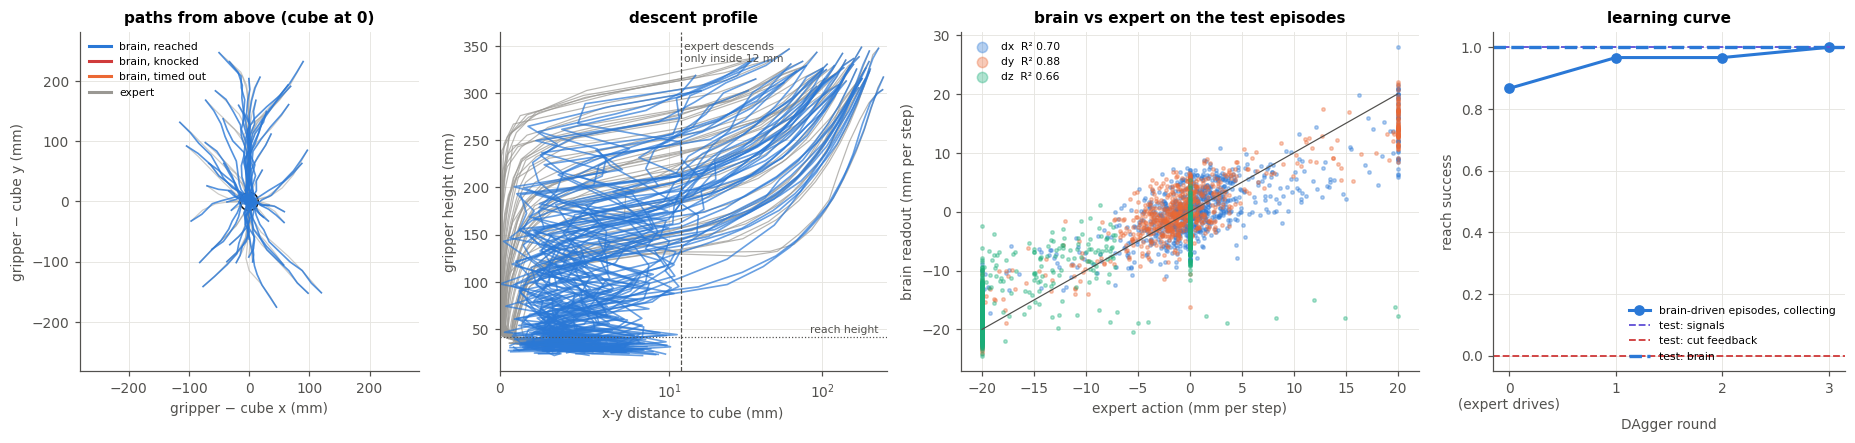

brain readout vs expert on test episodes, R²: {'dx': np.float64(0.7), 'dy': np.float64(0.881), 'dz': np.float64(0.665)}


In [7]:
outs_b, outs_e = RES['brain'][0], RES['expert'][0]
fig, axs = plt.subplots(1, 4, figsize=(17, 4.1), gridspec_kw=dict(width_ratios=[1, 1.1, 1.3, 1]))
ax = axs[0]
for o in outs_e:
    rel = -o['obs'][:, 16:18] * 1000                       # gripper minus cube, mm
    ax.plot(rel[:, 0], rel[:, 1], color=C['gray'], lw=0.8, alpha=0.5)
for o in outs_b:
    rel = -o['obs'][:, 16:18] * 1000
    cl = C['blue'] if o['success'] else (C['red'] if o['knocked'] else C['orange'])
    ax.plot(rel[:, 0], rel[:, 1], color=cl, lw=1.1, alpha=0.8)
ax.add_patch(plt.Circle((0, 0), REACH_XY * 1000, fill=False, color=C['ink'], lw=1))
lim = 1.05 * max(np.abs(ax.get_xlim()).max(), np.abs(ax.get_ylim()).max())
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect('equal')
ax.set_xlabel('gripper − cube x (mm)'); ax.set_ylabel('gripper − cube y (mm)')
ax.set_title('paths from above (cube at 0)')
ax.plot([], [], color=C['blue'], label='brain, reached'); ax.plot([], [], color=C['red'], label='brain, knocked')
ax.plot([], [], color=C['orange'], label='brain, timed out'); ax.plot([], [], color=C['gray'], label='expert')
ax.legend(fontsize=7, loc='upper left')

ax = axs[1]
for o, cl, lw in [(o, C['gray'], 0.8) for o in outs_e] + [(o, C['blue'] if o['success'] else C['red'], 1.1) for o in outs_b]:
    d = np.hypot(*o['obs'][:, 16:18].T) * 1000
    ax.plot(d, o['obs'][:, 2] * 1000, color=cl, lw=lw, alpha=0.7)
ax.axvline(12, color=C['ink2'], lw=0.8, ls='--'); ax.axhline(REACH_Z * 1000, color=C['ink2'], lw=0.8, ls=':')
ax.set_xscale('symlog', linthresh=10); ax.set_xlim(0, None)
ax.text(12.5, 0.97, 'expert descends\nonly inside 12 mm', transform=ax.get_xaxis_transform(), fontsize=7,
        color=C['ink2'], va='top')
ax.text(0.98, REACH_Z * 1000 + 4, 'reach height', transform=ax.get_yaxis_transform(), ha='right', fontsize=7, color=C['ink2'])
ax.set_xlabel('x-y distance to cube (mm)'); ax.set_ylabel('gripper height (mm)')
ax.set_title('descent profile')

ax = axs[2]
A = np.concatenate([o['A'] for o in outs_b]); Yb = np.concatenate([o['Y'] for o in outs_b])
R2_TEST = r2(Yb, A)
for j, (nm, cl) in enumerate(zip(ACT, (C['blue'], C['orange'], C['aqua']))):
    ax.scatter(Yb[:, j] * 1000, A[:, j] * 1000, s=5, alpha=0.35, color=cl, label=f"{nm}  R² {R2_TEST[j]:.2f}")
ax.plot([-20, 20], [-20, 20], color=C['ink2'], lw=0.8)
ax.set_xlabel('expert action (mm per step)'); ax.set_ylabel('brain readout (mm per step)')
ax.set_title('brain vs expert on the test episodes'); ax.legend(fontsize=7, markerscale=3)

ax = axs[3]
x = np.arange(len(DLOG))
ax.plot(x, [r['success'] for r in DLOG], marker='o', color=C['blue'], label='brain-driven episodes, collecting')
ax.set_xticks(x, ['0\n(expert drives)'] + [str(i) for i in x[1:]]); ax.set_xlabel('DAgger round')
for k, cl, lw in (('signals', C['violet'], 1.2), ('cut feedback', C['red'], 1.2), ('brain', C['blue'], 2.2)):
    ax.axhline(RES[k][1]['success_rate'], color=cl, lw=lw, ls='--', label=f"test: {k}")
ax.set_ylim(-0.05, 1.05); ax.set_ylabel('reach success'); ax.set_title('learning curve')
ax.legend(fontsize=7, loc='lower right')
fig.tight_layout(); fig.savefig(OUT / f'week6_summary_{HOST}.png', bbox_inches='tight'); plt.show()
print("brain readout vs expert on test episodes, R²:", dict(zip(ACT, R2_TEST.round(3))))

## Step 5: the video (deliverable)

Re-runs three test episodes with recording on (two successes and the first failure, if there is one) and checks that each re-run reproduces the test result exactly, since the brain and physics are seeded. The video shows the arm on the left and, on the right, the DN-candidate spikes driving it plus the decoded action against what the expert would have done. Played at half speed.

Rendering needs an OpenGL backend. It tries EGL, then OSMesa, then a window. On WSL, if none work, `sudo apt install libosmesa6` usually fixes it; otherwise the episodes are saved to `week6_episodes.pkl` and the last line printed tells you how to render them on Colab.

In [8]:
succ = [o['seed'] for o in outs_b if o['success']]
fail = [o['seed'] for o in outs_b if not o['success']]
PICK = (succ[:1] if QUICK else succ[:2] + fail[:1]) or [outs_b[0]['seed']]

Wfull = np.zeros((len(COLS['DN candidates']), 3)); Wfull[READOUT.ok] = READOUT.W
dn_order = np.lexsort((-np.abs(Wfull).max(1), np.abs(Wfull).argmax(1)))   # grouped by the action each DN pushes

EPISODES = []
for sd in PICK:
    o = run_episode(env, pol, expert, sd, record=True)
    ref = next(x for x in outs_b if x['seed'] == sd)
    same = (o['success'], o['steps'], o['n']) == (ref['success'], ref['steps'], ref['n'])
    print(f"seed {sd}: {'reached' if o['success'] else 'failed'} in {o['n']} steps; "
          f"re-run matches the test run: {same}")
    EPISODES.append(dict(rec=o['rec'], seed=sd, success=o['success'], knocked=o['knocked'],
                         steps=o['steps'], dn_order=dn_order))
pickle.dump(EPISODES, open(OUT / 'week6_episodes.pkl', 'wb'))

from sim.video import render
VIDEO = OUT / f'week6_fly_reach_{HOST}.mp4'
GL = render(str(OUT / 'week6_episodes.pkl'), str(VIDEO), slow=0.5)
if GL:
    from IPython.display import Video
    display(Video(str(VIDEO), embed=True, width=900))

seed 90000: reached in 21 steps; re-run matches the test run: True
seed 90001: reached in 23 steps; re-run matches the test run: True
  egl: failed (ModuleNotFoundError: No module named 'imageio')
  osmesa: failed (AttributeError: 'NoneType' object has no attribute 'glGetError')
  glfw: failed (ModuleNotFoundError: No module named 'imageio')
No OpenGL backend worked here. Copy the .pkl to Colab and run: !MUJOCO_GL=egl python -m sim.video episodes.pkl reach.mp4


## Step 6: results file

In [9]:
def s_json(s): return {k: (list(v) if isinstance(v, tuple) else v) for k, v in s.items()}
summary = dict(
    host=HOST, quick=QUICK, w_scale=W, encoder=ENC.kind, readout='DN candidates (68), 40 ms window, ridge',
    brain_ms_per_step=pol.brain_ms, dagger=dict(rounds=N_ROUNDS, episodes_per_round=N_PER_ROUND, betas=BETAS,
                                                log=DLOG, rows=int(len(DD['Y']))),
    readout_alpha=READOUT.alpha, action_r2_dagger_cv={k: dict(zip(ACT, map(float, v))) for k, v in R2_DAGGER.items()},
    action_r2_test=dict(zip(ACT, map(float, R2_TEST))),
    fallback_used=FALLBACK is not None,
    results={k: s_json(v[1]) for k, v in RES.items()}, pass_rule='brain >= 70% and > cut feedback', passed=bool(PASS),
    video=str(VIDEO) if GL else None, video_seeds=PICK, brain_s=io.sim_ms / 1000,
    wall_min=(time.perf_counter() - T_START) / 60)
(OUT / f'week6_results_{HOST}.json').write_text(json.dumps(summary, indent=1, default=float))
print(f"{'PASS' if PASS else 'FAIL'}: fly brain reaches {b['success']}/{b['n']} "
      f"({b['success_rate']:.0%}, 95% CI {b['ci'][0]:.0%}-{b['ci'][1]:.0%}); cut feedback {cut['success_rate']:.0%}")
print(f"total {summary['wall_min']:.0f} min. Send me week6_results_{HOST}.json, week6_summary_{HOST}.png "
      f"and the video from {OUT}.")

PASS: fly brain reaches 50/50 (100%, 95% CI 93%-100%); cut feedback 0%
total 20 min. Send me week6_results_laptop.json, week6_summary_laptop.png and the video from /home/notlord/arm_simulation/brain/data/week6.
